# AlphaScout walkthrough: can the validation catch its own weaknesses?

Everything here runs on **synthetic markets with known ground truth** (no real-market claims).
Two worlds: `planted` (a real momentum edge exists) and `noise` (no tradable structure at all).
A sound pipeline must find the edge in the first and **nothing** in the second.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, polars as pl, matplotlib.pyplot as plt
from alphascout.data.synthetic import generate_synthetic, noise_world
from alphascout.data.pit_store import PITStore
from alphascout.pipeline import run_pipeline, PipelineConfig
plt.rcParams['figure.figsize'] = (8, 3.2)
planted = generate_synthetic(70, 1600, seed=5, planted_momentum=3.0)
noise = noise_world(70, 1600, seed=8)
print(planted.prices.shape, 'bars;', int((~planted.truth['survivor']).sum()), 'delisted names kept in the universe')

(96987, 9) bars; 12 delisted names kept in the universe


## 1. Data layer: returns rebuilt from raw prices + corporate actions, bad ticks rejected
The synthetic generator knows the true returns, so we can check the store against them.

In [2]:
store = PITStore(planted); P = store.build_panel()
tr = planted.truth['ret']; got = P['ret']
log = store.rejection_log()
print(log.group_by('rule').len().sort('rule'))
inj = planted.truth['bad_ticks']; caught = {(s,d) for s,d in zip(log['symbol'], log['date'])}
print('injected bad ticks caught:', sum((s,d) in caught for s,d in zip(inj['symbol'], inj['date'])), 'of', inj.height)
print('unrecorded splits quarantined:', sum((s,d) in caught for s,d,_ in planted.truth['unrecorded_splits']), 'of', len(planted.truth['unrecorded_splits']))
ok = np.isfinite(tr) & np.isfinite(got)
print('cells whose reconstructed return differs from truth by >1e-9 (all sit next to a logged rejection):', int((np.abs(tr-got)[ok] > 1e-9).sum()), 'of', int(ok.sum()))

shape: (4, 2)
┌───────────────────────────┬─────┐
│ rule                      ┆ len │
│ ---                       ┆ --- │
│ str                       ┆ u32 │
╞═══════════════════════════╪═════╡
│ bad_tick_spike_revert     ┆ 30  │
│ nonpositive_or_null_price ┆ 3   │
│ ohlc_inconsistent         ┆ 5   │
│ suspect_unadjusted_action ┆ 4   │
└───────────────────────────┴─────┘
injected bad ticks caught: 38 of 38
unrecorded splits quarantined: 4 of 4
cells whose reconstructed return differs from truth by >1e-9 (all sit next to a logged rejection): 38 of 96887


## 2. Leakage detector (truncation test)
A causal function gives identical output on a truncated panel; any use of the future breaks that.

In [3]:
from alphascout.features.leakage import truncation_audit
from alphascout.features.core import momentum
fs = {'momentum (causal)': lambda p: momentum(p['logp'], 60, 5),
      'next-day return (shift -1)': lambda p: np.vstack([p['ret'][1:], np.full((1, p.A), np.nan)]),
      'full-sample z-score': lambda p: (p['logp']-np.nanmean(p['logp'],0))/np.nanstd(p['logp'],0)}
for n, f in fs.items(): print(truncation_audit(f, P, n))

[OK]   momentum (causal): causal at 3 cut points
[LEAK] next-day return (shift -1): uses future data (first divergent row 719 when truncated at 720, max |diff|=0.0436)
[LEAK] full-sample z-score: uses future data (first divergent row 0 when truncated at 720, max |diff|=3.37)


## 3. The gate on a market with no edge vs one with an edge

In [4]:
cfg = PipelineConfig(n_candidates=48, rw_bootstrap=500)
res_n = run_pipeline(noise, cfg, outdir='/tmp/nb_noise', verbose=False)
res_p = run_pipeline(planted, cfg, outdir='/tmp/nb_planted', verbose=False)
for name, r in [('NOISE', res_n), ('PLANTED', res_p)]:
    g = r['gate']
    print(f"{name:8s} best raw Sharpe {g['best_raw_sharpe_annualised']:5.2f} | SR0 (luck benchmark) {g['sr0_annualised']:4.2f} | PBO {g['pbo']:.2f} | "
          f"naive-significant {g['n_naive_significant']:2d} -> survivors {g['n_survivors']:2d}")

NOISE    best raw Sharpe  0.96 | SR0 (luck benchmark) 1.00 | PBO 0.29 | naive-significant  3 -> survivors  0
PLANTED  best raw Sharpe  4.06 | SR0 (luck benchmark) 1.00 | PBO 0.00 | naive-significant 11 -> survivors 11


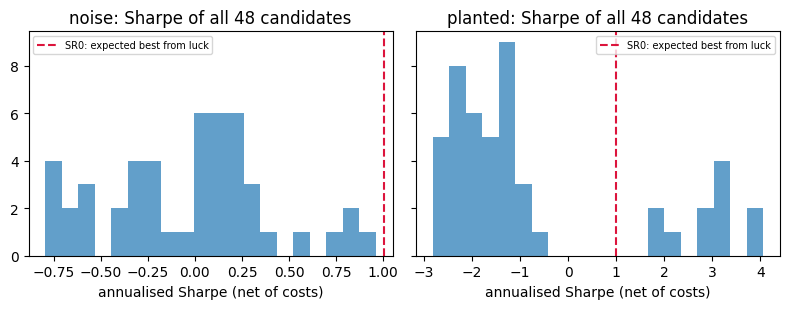

In [5]:
fig, ax = plt.subplots(1, 2, sharey=True)
for a, (name, r, d) in zip(ax, [('noise', res_n, '/tmp/nb_noise'), ('planted', res_p, '/tmp/nb_planted')]):
    c = pl.read_csv(f'{d}/candidates.csv')
    a.hist(c['research_sharpe_ann'].drop_nulls(), bins=20, color='tab:blue', alpha=.7)
    a.axvline(r['gate']['sr0_annualised'], color='crimson', ls='--', label='SR0: expected best from luck')
    a.set_title(f'{name}: Sharpe of all {r["config"]["n_candidates"]} candidates'); a.set_xlabel('annualised Sharpe (net of costs)'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. PBO: how often does the in-sample winner land in the bottom half out-of-sample?

In [6]:
from alphascout.validation.pbo import cscv_pbo
for name, d in [('noise', '/tmp/nb_noise'), ('planted', '/tmp/nb_planted')]:
    R = np.load(f'{d}/returns_matrix.npy')[: int(1600*0.8)]
    p = cscv_pbo(R, 16)
    print(f'{name:8s} PBO = {p.pbo:.2f}   P(OOS loss of the selected strategy) = {p.prob_oos_loss:.2f}   n_combos = {p.n_combos}')

noise    PBO = 0.29   P(OOS loss of the selected strategy) = 0.33   n_combos = 12870
planted  PBO = 0.00   P(OOS loss of the selected strategy) = 0.00   n_combos = 12870


## 5. Risk controls under a regime break
Factor reversal: past winners crash, losers rally, on top of a common selloff. A momentum book should hit the drawdown halt.

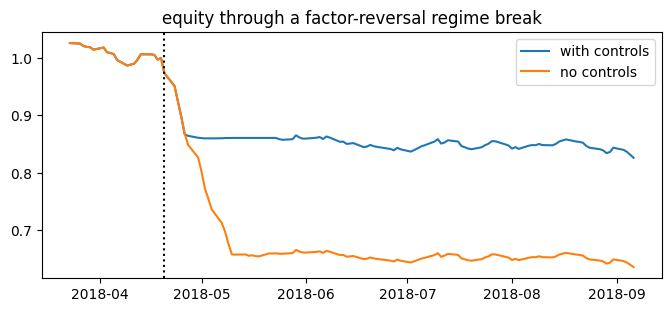

[('2018-04-25', 'drawdown_halt'), ('2018-08-23', 'delisting_liquidation')]


In [7]:
from alphascout.features.cache import FeatureCache
from alphascout.strategies.momentum import CSMomentum
from alphascout.backtest.event_sim import simulate, ExecConfig
from alphascout.robustness.shocks import factor_reversal
Pn = PITStore(noise).build_panel(); W = CSMomentum(60,5,5,0.2).weights(Pn, FeatureCache(Pn))
Pb = factor_reversal(Pn, 600, 15, strength=0.02)
on, off = simulate(Pb, W, ExecConfig()), simulate(Pb, W, ExecConfig().no_controls())
plt.plot(Pb.dates[580:700], on.equity[580:700]/on.equity[599], label='with controls')
plt.plot(Pb.dates[580:700], off.equity[580:700]/off.equity[599], label='no controls'); plt.axvline(Pb.dates[600], color='k', ls=':'); plt.legend(); plt.title('equity through a factor-reversal regime break'); plt.show()
print([ (e['date'], e['control']) for e in on.events if '2018' <= e['date'][:4] <= '2019'][:6])

## Takeaways
* On `noise`, candidates look significant *before* correction (the naive count) and nothing survives the gate.
* On `planted`, the edge is found and only the family that carries it survives; hold-out and cost/latency replay then test it again.
* The deflation uses the *number of candidates tried*, so widening the search makes the bar higher, by design.